# CIFAR-10 Image Classification

### Datasets and dataloaders

Dataset: stores samples and labels  
Dataloader: wraps iterable around dataset

In [1]:
#we will use a pre built dataset in this code so thats why i am not importing Dataset
import torch
from torchvision import datasets
from torchvision.transforms import v2
import torch.nn.functional as F
import torch.optim as optim

train_data = datasets.CIFAR10(root='data', train=True, download=True, transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]))
test_data = datasets.CIFAR10(root='data', train=False, download=True, transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]))

/mnt/13198402-5bc3-4484-b2e7-b656d5cdbb5b/Learning_Pytorch/.venv/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


in above cell transform are given which are applied each image before feeding it  
transform are handled by dataset not loader because dataset deals with single image  
  
One more thing:  
transform attribute is for features
target_transform is for labels

Text(0.5, 1.0, '6')

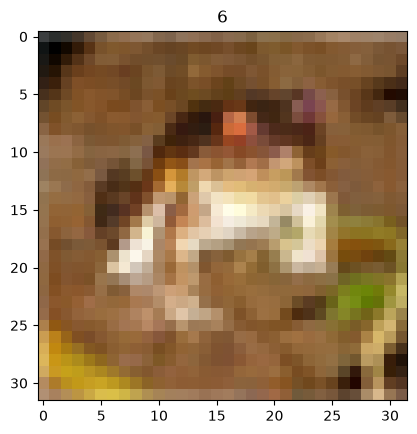

In [2]:
#Visualizing from dataset

import matplotlib.pyplot as plt

img, label = train_data[0]
plt.imshow(img.permute(1, 2, 0))
plt.title(label)

In [3]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Iterating in the dataset  
In below example we are using python iterators  

In [4]:
train_features, train_labels = next(iter(train_dataloader))
print(train_features.shape, train_labels.shape)

torch.Size([64, 3, 32, 32]) torch.Size([64])


### Creating the model

This model was explained by andrew ng and is like lenet

In [5]:
import torch.nn as nn

class  SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5, stride=1)
        self.bn1 = nn.BatchNorm2d(6)
        self.relu1 = nn.ReLU()
        self.maxpool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=10, kernel_size=5, stride=1)
        self.bn2 = nn.BatchNorm2d(10)
        self.relu2 = nn.ReLU()
        self.maxpool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(250, 120)
        self.bn3 = nn.BatchNorm1d(120)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(120, 60)
        self.bn4 = nn.BatchNorm1d(60)
        self.relu4 = nn.ReLU()
        self.fc3 = nn.Linear(60, 10)
    
    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = self.maxpool2(x)
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.bn3(x)
        x = self.relu3(x)
        x = self.fc2(x)
        x = self.bn4(x)
        x = self.relu4(x)
        x = self.fc3(x)
        return x

choosing device, creating model and loading model to the device

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [7]:
model = SimpleCNN().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

### Training the model

In [8]:
epochs = 10
for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for X,y in train_dataloader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        outputs = model(X)
        loss = loss_function(outputs, y)
        loss.backward()
        optimizer.step()

        running_loss +=loss.item()

    average_loss = running_loss / len(train_dataloader)
    print(f"Epoch {epoch+1}/{epochs} - Loss: {average_loss:.4f}", end=' ')

    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for images, labels in train_dataloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1) 
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total
        print(f'Train Set Accuracy: {accuracy:.2f}%', end=' ')

    model.eval() 
    with torch.no_grad(): 
        correct = 0
        total = 0
        for images, labels in test_dataloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total
        print(f'Test Set Accuracy: {accuracy:.2f}%')

Epoch 1/10 - Loss: 1.4680 Train Set Accuracy: 54.90% Test Set Accuracy: 53.56%
Epoch 2/10 - Loss: 1.1989 Train Set Accuracy: 57.84% Test Set Accuracy: 56.00%
Epoch 3/10 - Loss: 1.0904 Train Set Accuracy: 62.70% Test Set Accuracy: 59.08%
Epoch 4/10 - Loss: 1.0242 Train Set Accuracy: 59.97% Test Set Accuracy: 56.75%
Epoch 5/10 - Loss: 0.9765 Train Set Accuracy: 65.44% Test Set Accuracy: 60.80%
Epoch 6/10 - Loss: 0.9378 Train Set Accuracy: 69.94% Test Set Accuracy: 63.90%
Epoch 7/10 - Loss: 0.9003 Train Set Accuracy: 67.48% Test Set Accuracy: 60.91%
Epoch 8/10 - Loss: 0.8680 Train Set Accuracy: 58.74% Test Set Accuracy: 53.45%
Epoch 9/10 - Loss: 0.8464 Train Set Accuracy: 72.11% Test Set Accuracy: 63.58%
Epoch 10/10 - Loss: 0.8230 Train Set Accuracy: 72.38% Test Set Accuracy: 63.17%


In [9]:
model.eval() 
with torch.no_grad(): 
    correct = 0
    total = 0
    for images, labels in train_dataloader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1) 
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Train Set Accuracy: {accuracy:.2f}%')

Train Set Accuracy: 72.38%


In [10]:
model.eval() 
with torch.no_grad(): 
    correct = 0
    total = 0
    for images, labels in test_dataloader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1) 
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Test Set Accuracy: {accuracy:.2f}%')

Test Set Accuracy: 63.17%
